In [1]:
import numba
import numpy as np
from profdata import load_profdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

/home/keke/.pixi/envs/py/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
@numba.jit(nopython=True, boundscheck=False)
def sim_matrix_impl(act_hash, res):
    N, K = act_hash.shape
    for i in range(N):
        for j in range(N):
            A = (act_hash[i] * act_hash[j]).sum() / 256
            B = (act_hash[i] + act_hash[j]).sum()
            res[i, j] = 1.0 * A / (B - A + 1)

def sim_matrix(act_hash):
    N, K = act_hash.shape
    act_hash = act_hash.astype(np.int32)
    res = np.empty((N, N), dtype=np.float32)
    sim_matrix_impl(act_hash, res)
    return res

In [3]:
data = load_profdata('pgo-data/boom_m_1.T1.prof.bin')

In [4]:
act_hash = data.threads[0].act_hash
act_hash

array([[  9,   0,   0, ...,   0,   0,   0],
       [ 51,  58,  56, ...,   0,   0,   0],
       [  0,  14,  11, ...,   0,   0,   0],
       ...,
       [ 18,   2,   0, ...,   0,   0,   0],
       [  7, 255, 255, ...,   0,   0,   0],
       [  9,   2,   0, ...,   0,   0,   0]],
      shape=(2328, 4096), dtype=uint8)

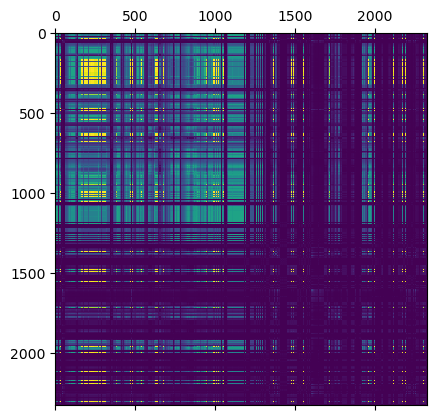

In [17]:
iou = sim_matrix(act_hash[:, :2048])
plt.matshow(iou, cmap='viridis')

In [21]:
np.save('prof-method-stat/bincount-method.npy', iou)

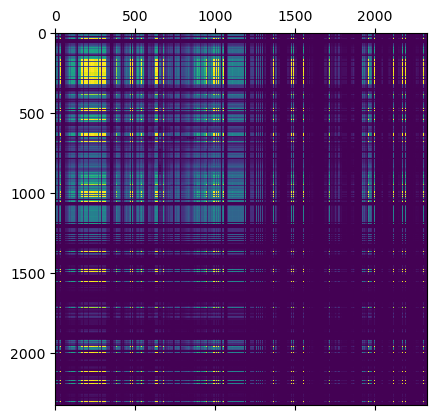

In [18]:
act_hash_p = act_hash[:, :2048].astype(np.float32)
sim = act_hash_p @ act_hash_p.T
plt.matshow(sim, cmap='viridis')

In [7]:
ground_truth = np.load('iou.npy')

In [10]:
np.abs(ground_truth - iou).mean()

np.float64(0.11359870008533889)